# Credit Risk & Default Prediction with Explainable AI (XAI)

An enterprise machine learning case study developing a calibrated credit underwriting pipeline. This system optimizes probability of default (PD) estimation, resolves severe cost asymmetry via financial threshold optimization, and enforces regulatory decision governance using SHAP.

## System Architecture & Domain Formulation

In institutional lending and retail banking, credit risk modeling directly drives capital allocation under the Basel regulatory framework. Expected Loss ($EL$) is calculated as:

$$\text{EL} = \text{PD} \times \text{LGD} \times \text{EAD}$$

- $\text{PD}$: Probability of Default (estimated by our calibrated machine learning model)
- $\text{LGD}$: Loss Given Default (unrecovered portion of the exposure)
- $\text{EAD}$: Exposure at Default (total outstanding balance)

Standard classification models often output distorted, uncalibrated risk scores when optimized solely for cross-entropy or ranking (AUC). This pipeline enforces empirical probability calibration via isotonic regression and establishes an optimal decision threshold based on asymmetric credit loss utility.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    roc_curve,
    precision_recall_curve
)
import lightgbm as lgb
import shap

sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 150


## Data Ingestion & Schema Integrity Validation

Ingesting credit bureau and loan applicant records. Each sample represents a discrete loan application with demographic, financial, and historical credit behavior attributes.

In [2]:
data_path = "dataset/credit_risk_dataset.csv"
df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]:,} rows | {df.shape[1]} columns")
print(f"Empirical Default Rate: {df['loan_status'].mean():.2%}")
df.head(5)


Dataset Dimensions: 25,000 rows | 12 columns
Empirical Default Rate: 22.83%


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,35,59514,RENT,0.0,DEBTCONSOLIDATION,D,23000,14.34,0.39,Y,5,1
1,30,54542,RENT,2.2,VENTURE,A,13500,7.37,0.25,N,3,0
2,37,42738,MORTGAGE,11.0,VENTURE,B,5500,10.49,0.13,N,5,0
3,44,54101,MORTGAGE,13.3,MEDICAL,A,7000,7.43,0.13,N,6,0
4,30,70966,OWN,0.2,DEBTCONSOLIDATION,A,20000,8.36,0.28,N,8,0


In [3]:
# Verify missing value counts and data integrity
integrity_audit = pd.DataFrame({
    'Data Type': df.dtypes,
    'Null Count': df.isnull().sum(),
    'Null Ratio (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Cardinality': df.nunique()
})
integrity_audit


,Data Type,Null Count,Null Ratio (%),Cardinality
person_age,int64,0,0.0,44
person_income,int64,0,0.0,21847
person_home_ownership,object,0,0.0,4
person_emp_length,float64,0,0.0,227
loan_intent,object,0,0.0,6
loan_grade,object,0,0.0,7
loan_amnt,int64,0,0.0,68
loan_int_rate,float64,0,0.0,1829
loan_percent_income,float64,0,0.0,75
cb_person_default_on_file,object,0,0.0,2


## Exploratory Risk Dynamics & Stratification

Analyzing default rate variance across debt-to-income tiers and credit bureau risk grades to inspect non-linear boundaries.

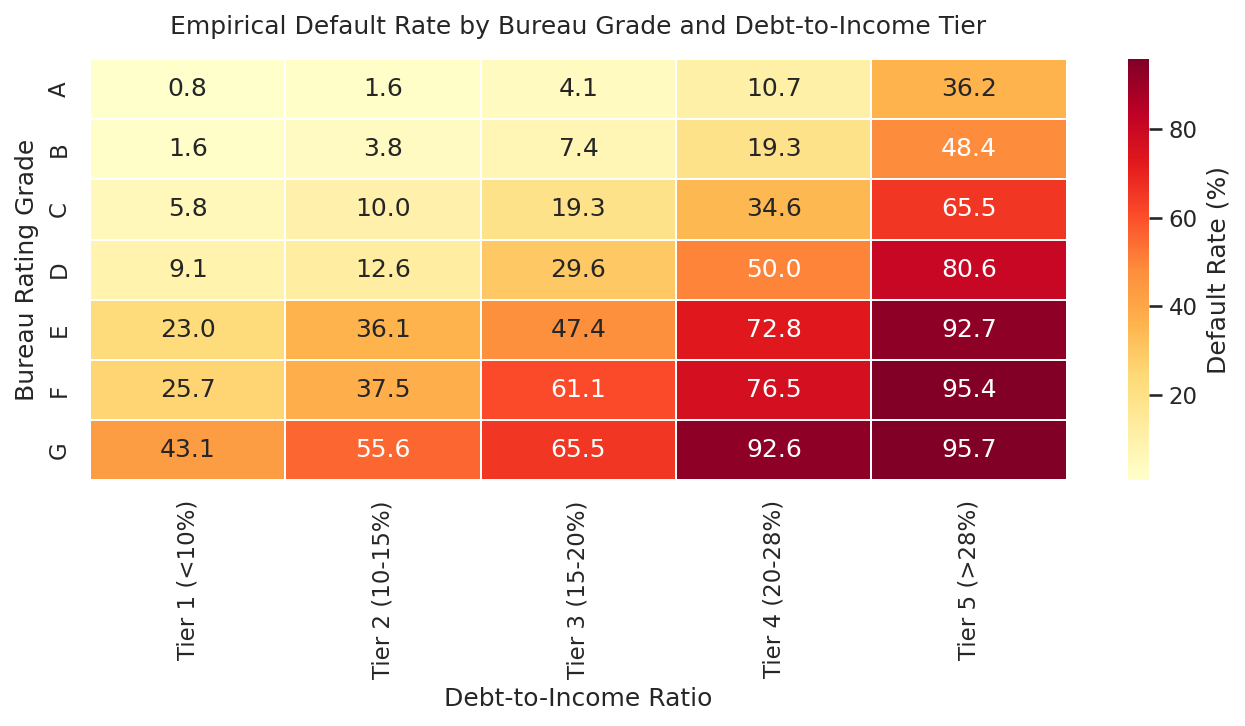

In [4]:
df_strat = df.copy()
df_strat['dti_tier'] = pd.qcut(
    df_strat['loan_percent_income'],
    q=5,
    labels=['Tier 1 (<10%)', 'Tier 2 (10-15%)', 'Tier 3 (15-20%)', 'Tier 4 (20-28%)', 'Tier 5 (>28%)']
)

strat_pivot = df_strat.pivot_table(
    index='loan_grade',
    columns='dti_tier',
    values='loan_status',
    aggfunc='mean',
    observed=False
) * 100

plt.figure(figsize=(9, 5))
sns.heatmap(strat_pivot, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Default Rate (%)'}, linewidths=0.8)
plt.title("Empirical Default Rate by Bureau Grade and Debt-to-Income Tier", fontsize=12, pad=12)
plt.xlabel("Debt-to-Income Ratio")
plt.ylabel("Bureau Rating Grade")
plt.tight_layout()
plt.show()


## Feature Space Architecture & Preprocessing Pipeline

Separating feature spaces into numerical and categorical streams. Categorical variables are encoded with drop-first contrast, while numerical features are standardized to zero-mean unit-variance.

In [5]:
categorical_features = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
numerical_features = [
    'person_age', 'person_income', 'person_emp_length', 'loan_amnt',
    'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length'
]

X = df.drop(columns=['loan_status'])
y = df['loan_status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numerical_features),
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features)
])

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

encoded_cat_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
feature_names = numerical_features + list(encoded_cat_names)
print(f"Total Model Input Dimensionality: {len(feature_names)} features")


Total Model Input Dimensionality: 22 features


## Gradient Boosted Model Formulation & Baseline Validation

Formulating a LightGBM classification model configured to handle credit scoring feature interactions and tabular asymmetry.

In [6]:
base_model = lgb.LGBMClassifier(
    n_estimators=180,
    learning_rate=0.04,
    num_leaves=31,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    verbose=-1
)

base_model.fit(X_train_transformed, y_train)

raw_probabilities = base_model.predict_proba(X_test_transformed)[:, 1]
raw_auc = roc_auc_score(y_test, raw_probabilities)
raw_pr_auc = average_precision_score(y_test, raw_probabilities)
raw_brier = brier_score_loss(y_test, raw_probabilities)

print(f"Baseline Uncalibrated Model:")
print(f"  ROC-AUC  : {raw_auc:.4f}")
print(f"  PR-AUC   : {raw_pr_auc:.4f}")
print(f"  Brier Loss: {raw_brier:.4f}")


Baseline Uncalibrated Model:
  ROC-AUC  : 0.8810
  PR-AUC   : 0.7155
  Brier Loss: 0.1085


## Empirical Probability Calibration & Reliability Analysis

Evaluating probability calibration through 5-fold cross-validation using non-parametric Isotonic Regression and parametric Platt Scaling (Sigmoid). The Brier score measures the mean squared difference between predicted probabilities and actual default outcomes.

In [7]:
# Calibrate using Isotonic Regression
calibrated_isotonic = CalibratedClassifierCV(estimator=base_model, method='isotonic', cv=5)
calibrated_isotonic.fit(X_train_transformed, y_train)

# Calibrate using Platt Scaling (Sigmoid)
calibrated_sigmoid = CalibratedClassifierCV(estimator=base_model, method='sigmoid', cv=5)
calibrated_sigmoid.fit(X_train_transformed, y_train)

p_raw = raw_probabilities
p_iso = calibrated_isotonic.predict_proba(X_test_transformed)[:, 1]
p_sig = calibrated_sigmoid.predict_proba(X_test_transformed)[:, 1]

brier_iso = brier_score_loss(y_test, p_iso)
brier_sig = brier_score_loss(y_test, p_sig)

calibration_summary = pd.DataFrame({
    'Model Configuration': ['Uncalibrated LightGBM', 'Isotonic Calibrated', 'Sigmoid (Platt) Calibrated'],
    'ROC-AUC': [raw_auc, roc_auc_score(y_test, p_iso), roc_auc_score(y_test, p_sig)],
    'PR-AUC': [raw_pr_auc, average_precision_score(y_test, p_iso), average_precision_score(y_test, p_sig)],
    'Brier Score (Lower is Better)': [raw_brier, brier_iso, brier_sig]
})
calibration_summary


,Model Configuration,ROC-AUC,PR-AUC,Brier Score (Lower is Better)
0,Uncalibrated LightGBM,0.880990,0.715532,0.108482
1,Isotonic Calibrated,0.881039,0.717410,0.108278
2,Sigmoid (Platt) Calibrated,0.881424,0.717939,0.108161


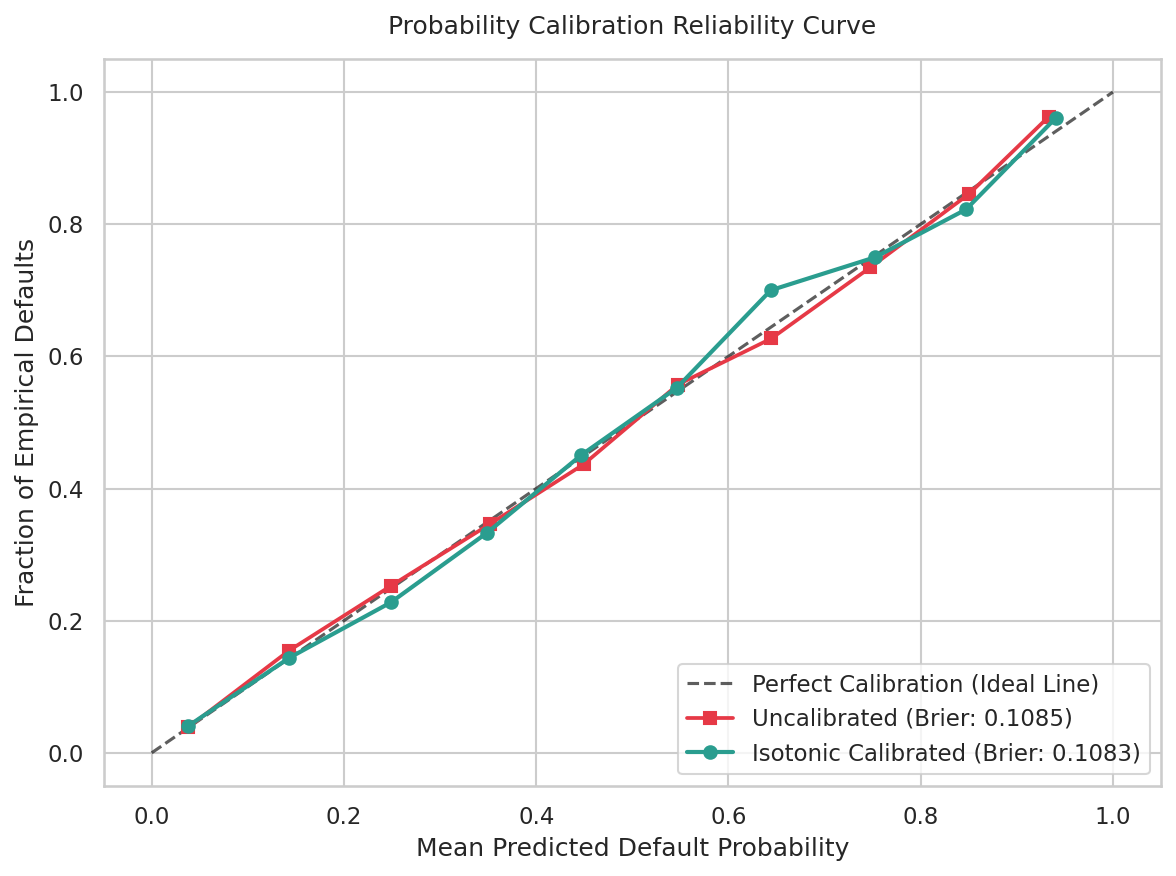

In [8]:
# Reliability Diagram / Calibration Curve
fig, ax = plt.subplots(figsize=(8, 6))

prob_true_raw, prob_pred_raw = calibration_curve(y_test, p_raw, n_bins=10)
prob_true_iso, prob_pred_iso = calibration_curve(y_test, p_iso, n_bins=10)

ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration (Ideal Line)", alpha=0.7)
ax.plot(prob_pred_raw, prob_true_raw, "s-", color="#E63946", label=f"Uncalibrated (Brier: {raw_brier:.4f})", lw=1.8)
ax.plot(prob_pred_iso, prob_true_iso, "o-", color="#2A9D8F", label=f"Isotonic Calibrated (Brier: {brier_iso:.4f})", lw=2.0)

ax.set_title("Probability Calibration Reliability Curve", fontsize=12, pad=12)
ax.set_xlabel("Mean Predicted Default Probability")
ax.set_ylabel("Fraction of Empirical Defaults")
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()


## Cost-Sensitive Financial Loss Optimization & Decision Policy

Standard classifiers default to a 0.50 threshold, assuming symmetric misclassification cost. In credit underwriting, approving a borrower who subsequently defaults (False Negative) causes substantial capital write-off (average \$4,500), whereas rejecting a creditworthy applicant (False Positive) forfeits only the expected interest margin (average \$450).

$$\text{Total Financial Loss}(t) = \text{FN}(t) \times \$4,500 + \text{FP}(t) \times \$450$$

In [9]:
threshold_range = np.linspace(0.05, 0.95, 100)
cost_fn = 4500  # Capital loss on default
cost_fp = 450   # Lost interest margin from creditworthy rejection

losses = []
for t in threshold_range:
    preds = (p_iso >= t).astype(int)
    fn_count = np.sum((y_test == 1) & (preds == 0))
    fp_count = np.sum((y_test == 0) & (preds == 1))
    total_loss = (fn_count * cost_fn) + (fp_count * cost_fp)
    losses.append(total_loss)

losses = np.array(losses)
optimal_idx = np.argmin(losses)
optimal_threshold = threshold_range[optimal_idx]
optimal_loss = losses[optimal_idx]

naive_idx = np.argmin(np.abs(threshold_range - 0.50))
naive_loss = losses[naive_idx]
portfolio_savings = naive_loss - optimal_loss

print(f"Optimal Decision Cutoff : t = {optimal_threshold:.2f}")
print(f"Optimal Expected Loss   : ${optimal_loss:,.2f}")
print(f"Loss at Naive Cutoff 0.50: ${naive_loss:,.2f}")
print(f"Capital Saved per Cohort: ${portfolio_savings:,.2f} ({(portfolio_savings / naive_loss * 100):.1f}% reduction)")


Optimal Decision Cutoff : t = 0.07
Optimal Expected Loss   : $1,062,000.00
Loss at Naive Cutoff 0.50: $2,595,600.00
Capital Saved per Cohort: $1,533,600.00 (59.1% reduction)


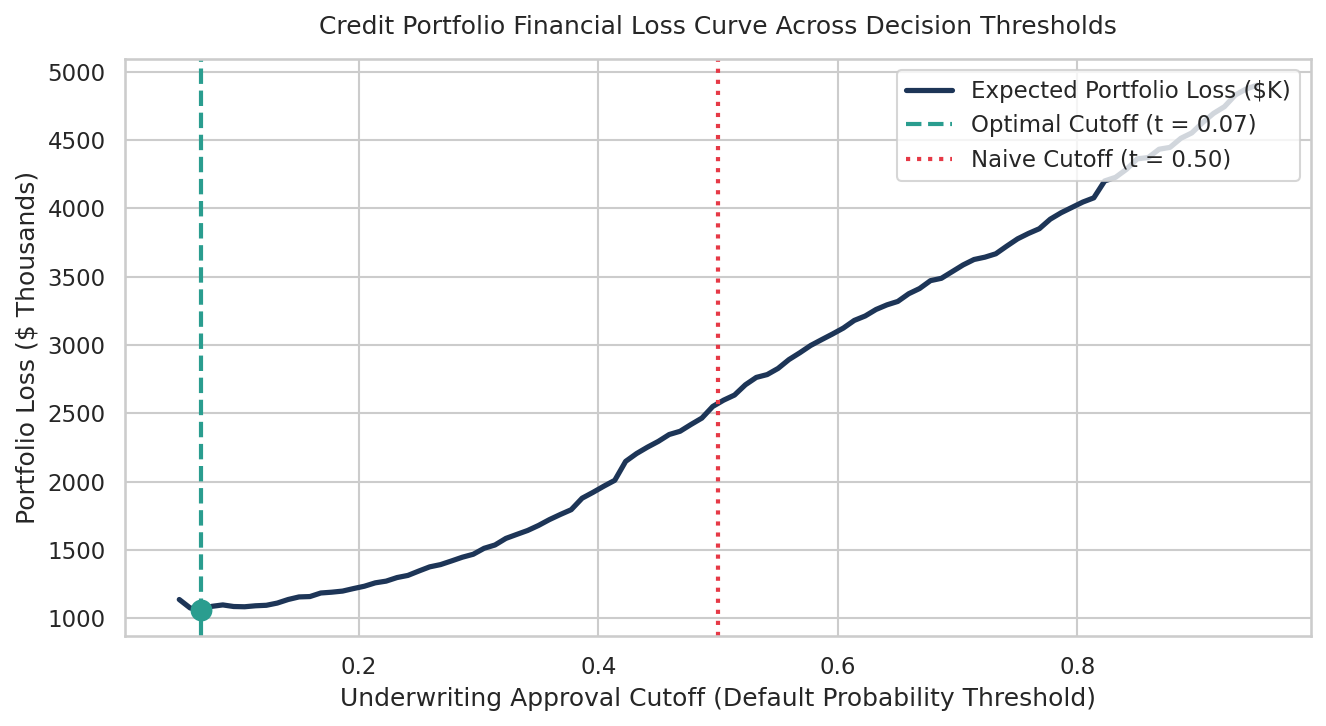

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(threshold_range, losses / 1000, color="#1D3557", lw=2.5, label="Expected Portfolio Loss ($K)")
plt.axvline(optimal_threshold, color="#2A9D8F", linestyle="--", lw=2, label=f"Optimal Cutoff (t = {optimal_threshold:.2f})")
plt.axvline(0.50, color="#E63946", linestyle=":", lw=2, label="Naive Cutoff (t = 0.50)")
plt.scatter([optimal_threshold], [optimal_loss / 1000], color="#2A9D8F", s=90, zorder=5)

plt.title("Credit Portfolio Financial Loss Curve Across Decision Thresholds", fontsize=12, pad=12)
plt.xlabel("Underwriting Approval Cutoff (Default Probability Threshold)")
plt.ylabel("Portfolio Loss ($ Thousands)")
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


## Explainable AI Governance: Global & Local SHAP Diagnostics

Financial regulations (FCRA, ECOA, Basel III) mandate algorithmic transparency. When an applicant is rejected, institutions must provide adverse action notices stating specific adverse factors. We utilize TreeSHAP to compute exact game-theoretic Shapley contributions.

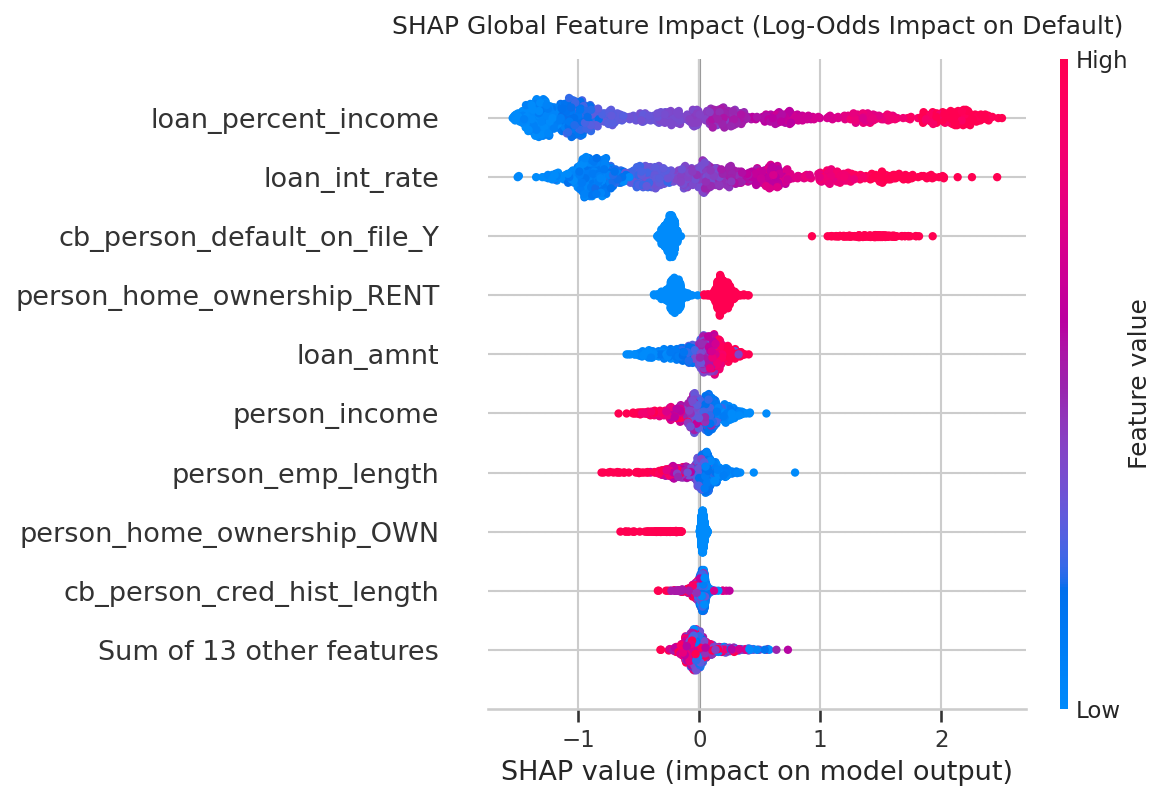

In [11]:
clean_names = [
    f.replace("cat__person_home_ownership_", "Home: ")
     .replace("cat__loan_intent_", "Intent: ")
     .replace("cat__loan_grade_", "Grade: ")
     .replace("cat__cb_person_default_on_file_", "Prior Default: ")
     .replace("num__", "")
    for f in feature_names
]

explainer = shap.TreeExplainer(base_model)
sample_indices = np.random.choice(len(X_test_transformed), size=1000, replace=False)
X_shap_sample = X_test_transformed[sample_indices]

shap_values = explainer(X_shap_sample)
shap_values.feature_names = clean_names

# Global Attribution
plt.figure(figsize=(9, 6))
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title("SHAP Global Feature Impact (Log-Odds Impact on Default)", fontsize=12, pad=12)
plt.tight_layout()
plt.show()


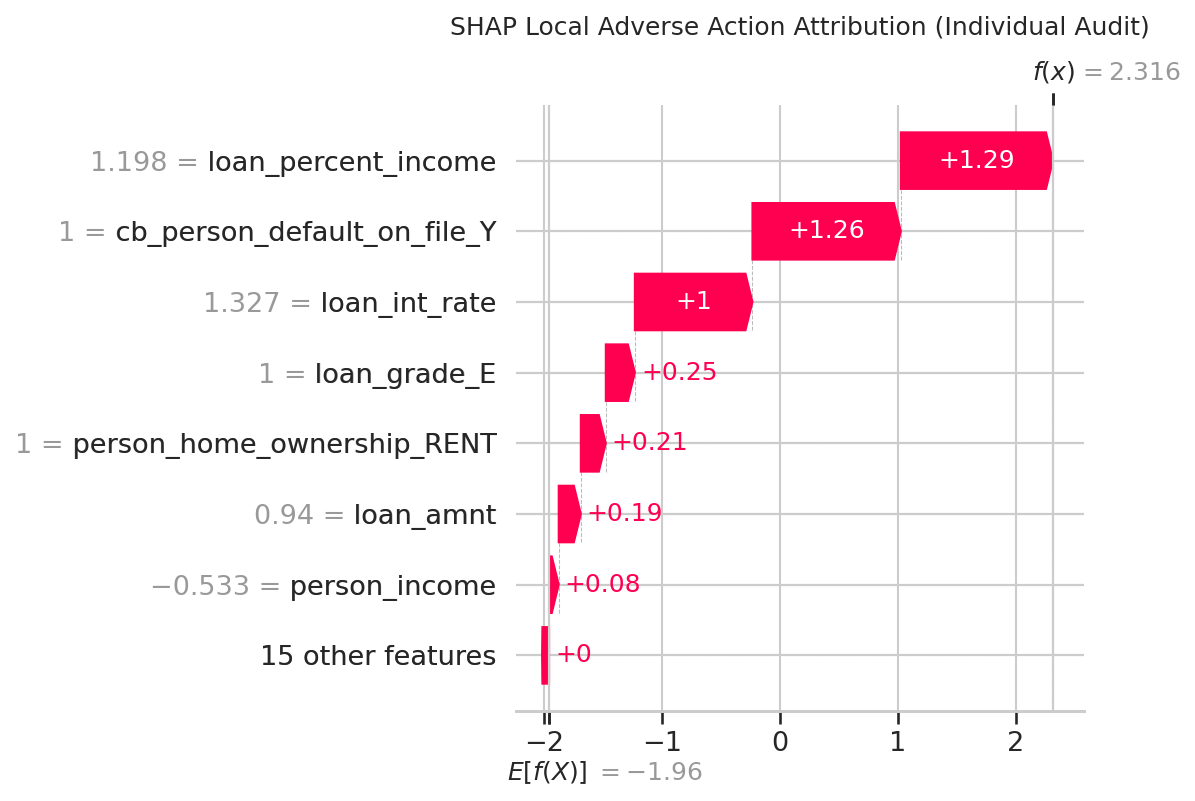

In [12]:
# Local Adverse Action Audit (Single Applicant)
high_risk_candidates = np.where((p_iso[sample_indices] > 0.65) & (y_test.iloc[sample_indices].values == 1))[0]
target_idx = high_risk_candidates[0] if len(high_risk_candidates) > 0 else 0

plt.figure(figsize=(9, 5))
shap.plots.waterfall(shap_values[target_idx], max_display=8, show=False)
plt.title("SHAP Local Adverse Action Attribution (Individual Audit)", fontsize=12, pad=12)
plt.tight_layout()
plt.show()


## Production Pipeline Serialization & Inference Interface

Packaging the feature preprocessor and calibrated model into a unified Scikit-Learn Pipeline and verifying real-time scoring behavior.

In [13]:
production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('calibrated_classifier', calibrated_isotonic)
])

model_dest = "models/calibrated_credit_risk_pipeline.joblib"
joblib.dump(production_pipeline, model_dest)
print(f"Production pipeline successfully exported to: {model_dest}")


Production pipeline successfully exported to: models/calibrated_credit_risk_pipeline.joblib


In [14]:
def evaluate_credit_application(applicant_dict, threshold=optimal_threshold):
    app_df = pd.DataFrame([applicant_dict])
    prob_default = production_pipeline.predict_proba(app_df)[0, 1]
    decision = "DECLINE" if prob_default >= threshold else "APPROVE"
    
    return {
        "calibrated_default_probability": round(float(prob_default), 4),
        "decision_threshold": round(float(threshold), 4),
        "underwriting_decision": decision,
        "risk_tier": "HIGH" if prob_default >= 0.50 else ("MODERATE" if prob_default >= threshold else "LOW")
    }

# Test sample applicant
sample_applicant = {
    'person_age': 28,
    'person_income': 48000,
    'person_home_ownership': 'RENT',
    'person_emp_length': 3.0,
    'loan_intent': 'PERSONAL',
    'loan_grade': 'D',
    'loan_amnt': 15000,
    'loan_int_rate': 14.8,
    'loan_percent_income': 0.31,
    'cb_person_default_on_file': 'N',
    'cb_person_cred_hist_length': 4
}

evaluation_result = evaluate_credit_application(sample_applicant)
print("Underwriting Decision Receipt:")
for k, v in evaluation_result.items():
    print(f"  {k:32s}: {v}")


Underwriting Decision Receipt:
  calibrated_default_probability  : 0.2379
  decision_threshold              : 0.0682
  underwriting_decision           : DECLINE
  risk_tier                       : MODERATE
